### Imports and Helper functions 
(#run this)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sym
from sympy import pprint
np.set_printoptions(linewidth=150)
import time
import collections


In [3]:
# defining useful funcitons.
def pp(M, rounding=3, imag_tolerance = 1e-12):
    if type(M) is not np.ndarray:
        print(M)
    else:
        M = M.real.round(rounding) + 1j*M.imag.round(rounding)
        if imag_tolerance is not None:
            M = np.where(np.abs(M.imag) < imag_tolerance, M.real, M)
        print(np.round(M, rounding))

def adj_line(q):            # function for creating adjacency matrix for a line graph of q vertices
    adj = np.zeros((q,q))
    for i in range(q):
        if i == 0:
            adj[i, i+1] = 1
        elif i == q-1:
            adj[i, i-1] = 1
        else:
            adj[i, i+1] = 1
            adj[i, i-1] = 1
    return adj


def sparse_to_dense(size, list, inv = False):       # list format : [[],[],[]] ...locations of ones
    l = len(list)
    s = size
    adj = np.zeros([s,s])
    print(adj.shape)

    for i in list:
        adj[i[0], i[1]] = 1
        adj[i[1], i[0]] = 1

    if inv:
        adj = np.ones(s,s) - adj

    return adj



### Defining Class objects - complete graphs only

In [4]:
class QuantumSystem:
    def __init__(self, q, alpha = 'auto'):
        self.q = q      # q is the number of main qubits, there are extra q ancilla qubits . Total 2*q qubits
        self.N = 2**q
        self.alpha = alpha

        self.psi0_a = self.superposition_state()
        self.zero_b = self.superposition_state(coeffs = [1] + [0]*(self.N-1))
        self.psi_kron_0 = np.kron(self.psi0_a, self.zero_b)
        
        self.I_a = np.eye(self.N)
        self.I_b = np.eye(self.N)
        self.Proj_ab = np.kron(self.I_a, self.zero_b @ self.zero_b.conj().T)    # projection operator - Identity on a, projection on |0> on b
        
        self.Phase = np.diag(self.phases(alpha))                      # phase operator from the phases, "U_a" in notes
        self.Swap = self.U_ab()                                                 # swap operator, "U_ab" in notes

        self.U_big = self.Swap @ (np.kron(self.Phase, self.I_b)) @ self.Swap      # full unitary matrix
        
    def matrix_basis(self): 
        q = self.q
        N = 2**q
        basis = []
        for i in range(N):
            state_i = np.zeros(N)
            state_i[i] = 1
            basis.append(state_i)
        return np.array(basis)

    def superposition_state(self, coeffs = 'maximal_except_0'):        # careful, dont include the zeros
        q = self.q
        N = self.N
        if coeffs == 'maximal_except_0':
            coeffs = np.ones(N)
            coeffs[0] = 0

        basis = self.matrix_basis()

        c = np.array(coeffs).reshape(1, N)
        c = c/np.sqrt(np.sum(np.abs(c)**2))  # normalizing 

        if basis.shape[1] != c.shape[1]:
            raise ValueError('Error: Shapes of coefficients and basis do not match')
        if len(coeffs) != N:            # checking length
            raise ValueError('Error: The number of coefficients is not 2^q')

        sup_state = np.sum(c * basis, axis = 1, keepdims = True)
        if (np.linalg.norm(sup_state)-1) > 1e-10:
            raise ValueError('Error: The resultant state is not normalized')
        return sup_state
    
    
    #defining the "partial swap" matrix for q qubits
    def U_ab(self):    
        q, N = self.q, self.N
        def kron_delta(a, b):
            return 1 if a == b else 0
        def U_mn(m,n):
            i, j = divmod(m, N)
            k, l = divmod(n, N)

            if k == 0 and l == 0:
                return (kron_delta(i, 0) * kron_delta(j, 0))
            elif k == 0 and l != 0:
                return (1/np.sqrt(2))*(kron_delta(i, 0) * kron_delta(j, l) - kron_delta(i, l) * kron_delta(j, 0))
            elif k != 0 and l == 0:
                return (1/np.sqrt(2))*(kron_delta(i, k) * kron_delta(j, 0) + kron_delta(i, 0) * kron_delta(j, k))
            else:
                return (kron_delta(i, k) * kron_delta(j, l))

        U = np.zeros((N**2, N**2))
        for m in range(N**2):       # create matrix using for loops - numpy gives errors
            for n in range(N**2):
                U[m, n] = U_mn(m, n)
        return U
    
    # def manual_cross_edges(self, adjacency_M, alpha = 'auto'):

    def phases(self, alpha = 'auto'):       # phases for the phase operator
        q, N = self.q, self.N
        # alpha is the coefficient in the Hamiltonian
        if q%2 == 0:            # creating alpha automatically, see notebook
            alpha = 4*np.pi/q**2
        else:
            alpha = 4*np.pi/(q**2-1)
        if alpha != 'auto':
            alpha = alpha           

        def qubit_sequence(a,q):                # to be used for creating a particular qubit sequence/permutation
            b = np.binary_repr(a, width = q)       # string     
            c = np.array([int(i) for i in b])   # array
            return c

        def edges_count(seq):   #seq is a binary sequence array
            p_0 = np.count_nonzero(seq == 0)
            p_1 = np.count_nonzero(seq == 1)
            return int(p_0*p_1)                 # for fully connected graph

        phases = []
        for i in range(N):
            cross_edges_i = edges_count(qubit_sequence(i, q))           # qubit sequence is creating a binary permutation (qubit states permutations) from the integer i from 0 to N-1.
            phase_i = np.exp(-1j*alpha*cross_edges_i)
            phases.append(phase_i)
        return np.array(phases)


    @staticmethod
    def norm_sq(state):        # returns sum of absolute squares ie. sum of probabilities
        return (np.abs(state)**2).sum()
    
    @staticmethod
    def normalize(state):
        if type(state) is not np.ndarray:
            raise ValueError('Error: State is not a numpy array')
        return (1/np.sqrt(QuantumSystem.norm_sq(state)))*state

        


### Defining Class for General graphs

In [5]:
# defining class for the general graph as q+q qubit quantum system.
# to take in adjacency matrix, number of qubits. Will have methods to calculate the phase operator, the swap operator, the full unitary matrix, the superposition state, the measurement operator etc.


class QuantumSystem:
    def __init__(self, q, adj_matrix):
        self.q = q      # q is the number of main qubits, there are extra q ancilla qubits . Total 2*q qubits
        self.N = 2**q
        self.basis_states = np.array([np.eye(self.N)[i] for i in range(self.N)])        # basis states for the q-qubits, list of N = 2^q states
        
        self.adj_matrix = adj_matrix
        self.E_t = np.sum(adj_matrix)/2      # total number of edges in the given graph
        self.alpha = -np.pi/(2*self.E_t)

        self.psi0 = self.superposition_state()                              # homogeneous superposition state in q system qubits, 2^q dim.
        self.zero = self.superposition_state(coeffs = [1] + [0]*(self.N-1))  # |0> state for q anicillas
        self.psi0_tensor_zero = np.kron(self.psi0, self.zero)                  # to be sent in, 2^(2q) dim.
        
        self.I_a, self.I_b = np.eye(self.N), np.eye(self.N)                     
    

        start_time = time.time()
        self.Swap = self.U_ab()                                                 # swap operator, "U_ab" in notes
        end_time = time.time()
        elapsed_time = end_time - start_time
        print(f'Elapsed time for q = {q}:', elapsed_time)    
        
        self.Proj_ab = np.kron(self.I_a, self.zero @ self.zero.conj().T)    # projection operator - Identity on the system, projection on |0> state of ancillas
        self.phase_list = self.phases(self.q, self.adj_matrix)      # list of phases ANGLES
        self.Phase = np.diag(np.exp(1j*self.phase_list))                      # phase operator from the phases, "U_a" in notes
    
        self.U_big = self.Swap @ (np.kron(self.Phase, self.I_b)) @ self.Swap      # full unitary matrix

    # instead of defining a method for creating matrix basis we will do it as a class variable
    
    def superposition_state(self, coeffs = 'maximal_except_0'):        # careful, dont include the zeros
        q = self.q
        N = self.N
        if coeffs == 'maximal_except_0':
            coeffs = np.ones(N)
            coeffs[0] = 0

        c = np.array(coeffs).reshape(1, N)
        c = c/np.sqrt(np.sum(np.abs(c)**2))

        if self.basis_states.shape[1] != c.shape[1]:
            raise ValueError('Error: Shapes of coefficients and basis do not match')
        if len(coeffs) != N:            # checking length
            raise ValueError('Error: The number of coefficients is not 2^q')
        
        sup_state = np.sum(c * self.basis_states, axis = 1, keepdims = True)
        if (np.linalg.norm(sup_state)-1) > 1e-10:
            raise ValueError('Error: The resultant state is not normalized')
        return sup_state

    #defining the "partial swap" matrix for q qubits
    def U_ab(self):    
        q, N = self.q, self.N
        def kron_delta(a, b):
            return 1 if a == b else 0
        def U_mn(m,n):
            i, j = divmod(m, N)
            k, l = divmod(n, N)

            if k == 0 and l == 0:
                return (kron_delta(i, 0) * kron_delta(j, 0))
            elif k == 0 and l != 0:
                return (1/np.sqrt(2))*(kron_delta(i, 0) * kron_delta(j, l) - kron_delta(i, l) * kron_delta(j, 0))
            elif k != 0 and l == 0:
                return (1/np.sqrt(2))*(kron_delta(i, k) * kron_delta(j, 0) + kron_delta(i, 0) * kron_delta(j, k))
            else:
                return (kron_delta(i, k) * kron_delta(j, l))

        U = np.zeros((N**2, N**2))
        for m in range(N**2):       # create matrix using for loops - numpy gives errors
            for n in range(N**2):
                U[m, n] = U_mn(m, n)
        return U


    # defining the phase operator after defining the phi_x function for an phase of an individual permutation/basis state

    @staticmethod
    def qubit_sequence(x, q):
        b = np.binary_repr(x, width = q)       # binary string for the integer/basis state x (out of 2**q states) 
        c = np.array([int(i) for i in b])       # eg. '101' -> [1, 0, 1]
        return c

    # permut_arr is the array for the basis state x (which is a permutation of q qubits)

    @staticmethod
    def cross_edges_max_arr(permut_arr):             #all possible cross edges for this permutation (will add graph adjacency matrix later)
        permut_arr[permut_arr == 0] = -1            # calling the zeroes as -1, for distinguishing the cross edges upon multiplication
        col_indices, row_indices = np.meshgrid(permut_arr, permut_arr)  # eg. for permutation 101, col_indices will have columns 1,-1 and 1; row_indices will have rows 1,-1 and 1.

        CE_raw = col_indices * row_indices      # cross edges are -1, rest are 1
        CE_raw = np.triu(CE_raw, k = 1)        # upper triangular part of the matrix to avoid double counting
        CE_raw[CE_raw == 1] = 0             # inverting, to change cross edges from 0 to -1 (and latter to 1)
        cross_edge_arr = (-1)*CE_raw                       # changing cross edges from -1 to 1
        return cross_edge_arr                    # returns upper triangular array of 1 and 0s, 1 for cross edge, 0 for self edge or no edge


    def phi_x(self, x, q, adj):                 # returns the angle phi for the basis state/partition x
        """ Returns phi and alpha for the particular basis state/partition x, given the adjacency matrix of the graph."""
        partition_string = self.qubit_sequence(x, q)
        partition_string_copy = partition_string.copy()

        C_E_max_arr_x = self.cross_edges_max_arr(partition_string_copy)
        total_edges = np.sum(adj) / 2  # adj is the adjacency matrix of the given graph
        C_E_actual = C_E_max_arr_x * adj
        C_E_count = np.sum(C_E_actual)
        alpha = -np.pi / (2 * total_edges)
        phi = -2 * alpha * C_E_count
        return phi


    def phases(self, q, adj_matrix):        # runs phi_x for all basis states/partitions; returns the list of PHASES (angles, NOT exponential of them) for the whole basis
        N = 2**q
        E_t = np.sum(adj_matrix)/2      # total number of edges in the given graph 

        phase_list = []
        for i in range(N):
            phase_list.append(self.phi_x(i, q, adj_matrix))
        phases = np.array(phase_list)
        return phases

    @staticmethod
    def norm_sq(state):        # returns sum of absolute squares ie. sum of probabilities
        return (np.abs(state)**2).sum()
    
    @staticmethod
    def normalize(state):
        if type(state) is not np.ndarray:
            raise ValueError('Error: State is not a numpy array')
        return (1/np.sqrt(QuantumSystem.norm_sq(state)))*state
    
    # @staticmethod
    # def tensor_div(arr,b):            # arr is tenosr prod of two states, b is the second state with all zeroes except one 1 at b'th position
    #     arr_copy = arr.copy()
    # @staticmethod
    # def state_to_qubit:


In [4]:
# create a function to iterate as before, to ultimately get bit strings with the highest probabilities
def iterate_system(q, adj_matrix, iterations = 3):
    start_time = time.time()
    
    Q = QuantumSystem(q, adj_matrix)
    psi = Q.psi0_tensor_zero
    U_big = Q.U_big
    prob_list, psi_iteration_list, psi_prime_list = [], [], []
    unnormalized_psi_list = []

    for i in range(iterations):
        psi_prime = U_big @ psi  # operated state
        psi_prime_list.append(psi_prime)

        psi_collapsed_unnorm = Q.Proj_ab @ psi_prime
        
        unnormalized_psi_list.append(psi_collapsed_unnorm)

        prob = Q.norm_sq(psi_collapsed_unnorm)
        prob_list.append(prob)
        psi = Q.normalize(psi_collapsed_unnorm)
        psi_iteration_list.append(psi)
        
    end_time = time.time()
    elapsed_time = end_time - start_time
    print(f'Elapsed time for q = {q}:', elapsed_time)
    return prob_list, psi,  psi_iteration_list, unnormalized_psi_list, Q.psi0_tensor_zero

In [12]:
# adj matrix for q = 8, linear

q = 8
adj_matrix = np.array([[0, 1, 0, 0, 0, 0, 0, 0],  [1, 0, 1, 0, 0, 0, 0, 0], [0, 1, 0, 1, 0, 0, 0, 0], [0, 0, 1, 0, 1, 0, 0, 0], [0, 0, 0, 1, 0, 1, 0, 0], [0, 0, 0, 0, 1, 0, 1, 0], [0, 0, 0, 0, 0, 1, 0, 1], [0, 0, 0, 0, 0, 0, 1, 0]])


# q = 4
# adj_matrix = np.array([[0, 1, 1, 0], 
#                          [1, 0, 1, 1],
#                         [1, 1, 0, 1],
#                         [0, 1, 1, 0]])

In [13]:
Q = QuantumSystem(q, adj_matrix)

Elapsed time for q = 8: 2130.7434911727905


: 

### Analytical Method (still full matrices)

In [4]:
# circumveniting Swap matrices by using analytical expressions

import numpy as np
class QuantumSystem:
    def __init__(self, q, adj_matrix):
        self.q = q      # q is the number of main qubits, there are extra q ancilla qubits . Total 2*q qubits
        self.N = 2**q
        
        self.adj_matrix = adj_matrix
        self.E_t = np.sum(adj_matrix)/2      # total number of edges in the given graph
        self.alpha = -np.pi/(2*self.E_t)
        
        #Cached variables
        self.cached_basis_states = None
        self.cached_psi0 = None
        self.cached_zero = None
        self.cached_psi0_tensor_zero = None
        self.cached_I_a =  None
        self.cached_Proj_ab = None
        self.cached_phase_list = None
        # self.cached_Phase = None
        # self.cached_Swap = None
        self.cached_U_big = None
        
        self.cached_prob1 = None
        self.cached_prob2 = None
        self.cached_psi_iter2 = None
        

    # instead of defining a method for creating matrix basis we will do it as a class variable
    @property
    def Identity_N(self):
        if self.cached_basis_states is None:
            self.cached_basis_states = np.eye(self.N)
        return self.cached_basis_states         # returns identity matrix of size 2^q = N
        
    @property
    def psi0(self):
        if self.cached_psi0 is None:
            self.cached_psi0 = (1/np.sqrt(self.N-1))*np.sum(self.Identity_N[1:], axis = 0, keepdims = True).T
        return self.cached_psi0
    
    @property
    def zero(self):
        if self.cached_zero is None:
            self.cached_zero = np.eye(self.N)[0].reshape(1, self.N).T
        return self.cached_zero

    @property
    def psi0_tensor_zero(self):
        if self.cached_psi0_tensor_zero is None:
            self.cached_psi0_tensor_zero = np.kron(self.psi0, self.zero)
        return self.cached_psi0_tensor_zero

    @property
    def Proj_ab(self):
        if self.cached_Proj_ab is None:
            self.cached_Proj_ab = np.kron(self.Identity_N, self.zero @ self.zero.conj().T)  # projection operator
        return self.cached_Proj_ab

    @property
    def phase_angles(self):
        if self.cached_phase_list is None:
            self.cached_phase_list = self.phases(self.q, self.adj_matrix).reshape(self.N, 1)     
        return self.cached_phase_list           # COLUMN of phases ANGLES

    @property
    def phase_list(self):       # column of phases (not angles)
        return np.exp(1j*self.phase_angles)
    
    
    @property
    def Phase(self):        # phase operator
        return np.diag(np.exp(1j*self.phase_angles.reshape(-1)))

    @property
    def p1(self):
        if self.cached_prob1 is None:
            self.cached_prob1 = (.25/(self.N-1))*((np.abs(self.phase_list[1:] - 1)**2).sum())
        return self.cached_prob1

    @property
    def p2(self):
        if self.cached_prob2 is None:
            self.cached_prob2 = (1/(16*(self.N-1)*self.p1))*((np.abs(self.phase_list[1:] - 1)**4).sum())
        return self.cached_prob2
    
    # @property
    # def psi_iter2(self):
    #     if self.cached_psi_iter2 is None:
    #         norm_coeff = 1/np.sqrt(4*(self.N -1)*self.p1*self.p2)
    #         psi_iter_2_a = norm_coeff*(((((self.phase_list[1:] - 1))**2)*self.Identity_N[1:]).sum(axis = 0, keepdims = True)).T
    #         self.cached_psi_iter2 = np.kron(psi_iter_2_a, self.zero)                        # projection/collapse on ancilla's zero state
    #     return self.cached_psi_iter2
    @property
    def psi_iter2(self):
        if self.cached_psi_iter2 is None:
            norm_coeff = 1/np.sqrt(4*(self.N -1)*self.p1*self.p2)
            psi_iter_2_a = norm_coeff*(((((self.phase_list[1:] - 1))**2)*self.Identity_N[1:]).sum(axis = 0, keepdims = True)).T
            self.cached_psi_iter2 = psi_iter_2_a                        # projection/collapse on ancilla's zero state
        return self.cached_psi_iter2

    @property
    def Swap(self):
        return self.U_ab()  
    
    @property
    def U_big(self):
        if self.cached_U_big is None:
            self.cached_U_big = self.Swap @ (np.kron(self.Phase, self.Identity_N)) @ self.Swap
        return self.cached_U_big

    #defining the "partial swap" matrix for q qubits
    def U_ab(self):    
        q, N = self.q, self.N
        def kron_delta(a, b):
            return 1 if a == b else 0
        def U_mn(m,n):
            i, j = divmod(m, N)
            k, l = divmod(n, N)

            if k == 0 and l == 0:
                return (kron_delta(i, 0) * kron_delta(j, 0))
            elif k == 0 and l != 0:
                return (1/np.sqrt(2))*(kron_delta(i, 0) * kron_delta(j, l) - kron_delta(i, l) * kron_delta(j, 0))
            elif k != 0 and l == 0:
                return (1/np.sqrt(2))*(kron_delta(i, k) * kron_delta(j, 0) + kron_delta(i, 0) * kron_delta(j, k))
            else:
                return (kron_delta(i, k) * kron_delta(j, l))

        U = np.zeros((N**2, N**2))
        for m in range(N**2):       # create matrix using for loops - numpy gives errors
            for n in range(N**2):
                U[m, n] = U_mn(m, n)
        return U

    # defining the phase operator after defining the phi_x function for an phase of an individual permutation/basis state

    @staticmethod
    def qubit_sequence(x, q):
        b = np.binary_repr(x, width = q)       # binary string for the integer/basis state x (out of 2**q states) 
        c = np.array([int(i) for i in b])       # eg. '101' -> [1, 0, 1]
        return c
    # permut_arr is the array for the basis state x (which is a permutation of q qubits)
    @staticmethod
    def cross_edges_max_arr(permut_arr):             #all possible cross edges for this permutation (will add graph adjacency matrix later)
        permut_arr[permut_arr == 0] = -1            # calling the zeroes as -1, for distinguishing the cross edges upon multiplication
        col_indices, row_indices = np.meshgrid(permut_arr, permut_arr)  # eg. for permutation 101, col_indices will have columns 1,-1 and 1; row_indices will have rows 1,-1 and 1.

        CE_raw = col_indices * row_indices      # cross edges are -1, rest are 1
        CE_raw = np.triu(CE_raw, k = 1)        # upper triangular part of the matrix to avoid double counting
        CE_raw[CE_raw == 1] = 0             # inverting, to change cross edges from 0 to -1 (and latter to 1)
        cross_edge_arr = (-1)*CE_raw                       # changing cross edges from -1 to 1
        return cross_edge_arr                    # returns upper triangular array of 1 and 0s, 1 for cross edge, 0 for self edge or no edge
    
    def phi_x(self, x, q, adj):                 # returns the angle phi for the basis state/partition x
        """ Returns phi and alpha for the particular basis state/partition x, given the adjacency matrix of the graph."""
        partition_string = self.qubit_sequence(x, q)
        partition_string_copy = partition_string.copy()

        C_E_max_arr_x = self.cross_edges_max_arr(partition_string_copy)
        total_edges = np.sum(adj) / 2  # adj is the adjacency matrix of the given graph
        C_E_actual = C_E_max_arr_x * adj
        C_E_count = np.sum(C_E_actual)
        alpha = -np.pi / (2 * total_edges)
        phi = -2 * alpha * C_E_count
        return phi

    def phases(self, q, adj_matrix):        # runs phi_x for all basis states/partitions; returns the list of PHASES angles, NOT exponential of them, for the whole basis
        N = 2**q
        E_t = np.sum(adj_matrix)/2      # total number of edges in the given graph 
        phase_list = []
        for i in range(N):
            phase_list.append(self.phi_x(i, q, adj_matrix))
        phases = np.array(phase_list)
        return phases

    @staticmethod
    def norm_sq(state):        # returns sum of absolute squares ie. sum of probabilities
        return (np.abs(state)**2).sum()
    
    @staticmethod
    def normalize(state):           # normalizes the state
        if type(state) is not np.ndarray:
            raise ValueError('Error: State is not a numpy array')
        return (1/np.sqrt(QuantumSystem.norm_sq(state)))*state
    
    # @staticmethod
    # def tensor_div(arr,b):            # arr is tenosr prod of two states, b is the second state with all zeroes except one 1 at b'th position
    #     arr_copy = arr.copy()
    # @staticmethod
    # def state_to_qubit:


In [6]:
#Works till q = 14. takes 5 sec
q = 16

adj14 = adj_line(q)

Q14 = QuantumSystem(q, adj14)

#############

ff = Q14.psi_iter2.T
ff_w = np.where(abs(ff) > .0141)
print(ff_w[1])                          # indices with high amplitude

partitions = np.array([format(i, '028b') for i in ff_w[1]])
partitions_a = np.array([ i[0:14] for i in partitions])

partitions_a, ff[0,ff_w[1]]     # working for q = 14, line graph

: 

In [ ]:
# for a 2D net of 9 qubits
q = 9

adj_line15 = np.array([[0, 1, 0 ,1, 0, 0, 0, 0, 0], [ 1,0,1,0,1,0,0,0,0], [0,1,0,0,0,1,0,0,0], [1,0,0,0,1,0,1,0,0], [0,1,0,1,0,1,0,1,0], [0,0,1,0,1,0,0,0,1], [0,0,0,1,0,0,0,1,0], [0,0,0,0,1,0,1,0,1], [0,0,0,0,0,1,0,1,0]])

Q9 = QuantumSystem(q, adj_line15)


In [10]:
ff = Q9.psi_iter2.T
ff_w = np.where(abs(ff) > .07)

prob1 = Q9.cached_prob1
prob2 = Q9.cached_prob2    #print probs
print('','prob1', prob1)
print('','prob2', prob2)

print(ff_w[1])                          # indices with high amplitude


partitions = np.array([format(i, '018b') for i in ff_w[1]])
partitions_a = np.array([ i[0:9] for i in partitions])

partitions_a, ff[0,ff_w[1]]     # working for q = 9, line graph

ordered_pairs = zip(ff[0,ff_w[1]], partitions_a)    
sorted_pairs = sorted(ordered_pairs, reverse = True)
sorted_pairs[:10]


 prob1 0.5009784735812132
 prob2 0.581896055895209
[  5120   7168   8704  10240  10752  13312  14336  14848  15360  17408
  17920  20480  20992  21504  22016  22528  23040  23552  25088  25600
  26112  27136  28672  29184  29696  30720  31232  35328  37888  39936
  40960  41472  41984  42496  43008  43520  44032  44544  46080  47104
  47616  48128  49664  50176  50688  51712  52224  52736  53248  53760
  54272  54784  55296  55808  56320  57344  57856  58368  58880  59392
  59904  60416  60928  61440  61952  62464  63488  64000  66560  67072
  68096  68608  69120  69632  70144  70656  71168  71680  72192  72704
  73216  74240  74752  75264  75776  76288  76800  77312  77824  78336
  78848  79872  80384  80896  81920  82432  82944  83456  83968  84480
  84992  85504  86016  86528  87040  87552  88064  88576  89088  89600
  90112  90624  91136  91648  92160  92672  94208  94720  95232  95744
  96256  96768  97280  99328  99840 100864 101376 101888 103424 104448
 104960 105472 107008 1075

[((0.1638654165225168-2.00677257835248e-17j), '101010101'),
 ((0.1638654165225168-2.00677257835248e-17j), '010101010'),
 ((0.13240533795105267-0.0764442575081837j), '110101010'),
 ((0.13240533795105267-0.0764442575081837j), '101010100'),
 ((0.13240533795105267-0.0764442575081837j), '101010001'),
 ((0.13240533795105267-0.0764442575081837j), '100010101'),
 ((0.13240533795105267-0.0764442575081837j), '011101010'),
 ((0.13240533795105267-0.0764442575081837j), '010101110'),
 ((0.13240533795105267-0.0764442575081837j), '010101011'),
 ((0.13240533795105267-0.0764442575081837j), '001010101')]

### Nth Analytical implementaion. Pushing efficiency to q > 23.

In [ ]:
# analytical, extending to nth iteration
import numpy as np
class QuantumSystem:
    def __init__(self, q, adj_matrix):
        self.q = q      # q is the number of main qubits, there are extra q ancilla qubits . Total 2*q qubits
        self.N = 2**q
        
        self.adj_matrix = adj_matrix
        self.E_t = np.sum(adj_matrix)/2      # total number of edges in the given graph
        self.alpha = -np.pi/(2*self.E_t)
        
        #Cached variables
        self.cached_basis_states = None
        self.cached_psi0 = None
        self.cached_zero = None
        self.cached_psi0_tensor_zero = None
        self.cached_I_a =  None
        self.cached_Proj_ab = None
        self.cached_phase_list = None
        # self.cached_U_big = None
        
        self.cached_probs = {0:1 }


        ###########
        self.cached_AbsSq_phase_minus_1 = self.abs_phase_minus_1()
        self.cached_probs = {0:1}                                       # list of probs for mth iter (not prod of probs)
        ###########
        self.cached_prob1 = None
        self.cached_prob2 = None
        self.cached_psi_iter2 = None
        

    # instead of defining a method for creating matrix basis..
    @property
    def Identity_N(self):
        if self.cached_basis_states is None:
            self.cached_basis_states = np.eye(self.N)
        return self.cached_basis_states         # returns identity matrix of size 2^q = N
        
    @property
    def psi0(self):
        if self.cached_psi0 is None:
            self.cached_psi0 = (1/np.sqrt(self.N-1))*np.sum(self.Identity_N[1:], axis = 0, keepdims = True).T
        return self.cached_psi0
    
    @property
    def zero(self):
        if self.cached_zero is None:
            self.cached_zero = np.eye(self.N)[0].reshape(1, self.N).T
        return self.cached_zero

    @property
    def psi0_tensor_zero(self):
        if self.cached_psi0_tensor_zero is None:
            self.cached_psi0_tensor_zero = np.kron(self.psi0, self.zero)
        return self.cached_psi0_tensor_zero

    @property
    def Proj_ab(self):
        if self.cached_Proj_ab is None:
            self.cached_Proj_ab = np.kron(self.Identity_N, self.zero @ self.zero.conj().T)  # projection operator
        return self.cached_Proj_ab

    @property
    def phase_angles(self):
        if self.cached_phase_list is None:
            self.cached_phase_list = self.phases(self.q, self.adj_matrix).reshape(self.N, 1)
        return self.cached_phase_list           # COLUMN of phases ANGLES

    @property
    def phase_list(self):       # column of phases (not angles)
        return np.exp(1j*self.phase_angles)
    
    @property
    def Phase(self):        # phase operator
        return np.diag(np.exp(1j*self.phase_angles.reshape(-1)))

    @property
    def p1(self):
        if self.cached_prob1 is None:
            self.cached_prob1 = (.25/(self.N-1))*((np.abs(self.phase_list[1:] - 1)**2).sum())
        return self.cached_prob1

    @property
    def p2(self):
        if self.cached_prob2 is None:
            self.cached_prob2 = ((1/16)/((self.N-1)*self.p1))*((np.abs(self.phase_list[1:] - 1)**4).sum())
        return self.cached_prob2


    def prob_m(self, m):
        if not m:
            return 1

        def prod_prob_m(m):
            if m == 0:
                return 1
            if m in self.cached_probs:              # using cached values recursively, if they exist in the dictionary
                return self.cached_probs[m]*prod_prob_m(m-1)
            
            p_minus_1 = prod_prob_m(m-1) 
            p = (1/((self.N-1)*(4**m)*p_minus_1))* np.sum(((self.cached_AbsSq_phase_minus_1)**m))   # mth prob
            self.cached_probs[m] = p                                            # caching the value of mth prob (not product prob)
            
            return p*p_minus_1

        prod_prob_m(m)
        p_m = self.cached_probs[m]                                              # 
        return p_m
    

    def abs_phase_minus_1(self):           # calc list from ONE to N of abs sq of e^(i*phi) -1. Done for efficiency 
        phases_from1 = np.array(self.phase_list.reshape(-1)[1:])
        phases_diff_abs_sq_from1 = np.abs(phases_from1-1)**2             # (e**i*phi -1)**2 for all except the first elt. len = 2**q -1
        return phases_diff_abs_sq_from1

    def psi_iter_m(self,m):         # state after mth iteration
        if m not in self.cached_probs:
            self.prob_m(m)
        prod_probs_m = 1
        for i in range(m+1):                    # product of probs from 0 to m (m+1 not included)
            prod_probs_m *= self.cached_probs[i]

        denominator = (2**m)* np.sqrt((self.N-1)* prod_probs_m)

        phases = self.phase_list.reshape(-1)       # phases (not angles). Including the first one coz it is zero anyways, but will affect binary representation
        sum_qm_states = np.power(phases-1, m)        #quantum state except the prefactor

        return (1/denominator)*sum_qm_states


    @property
    def Swap(self):
        return self.U_ab()  
    
    @property
    def U_big(self):
        if self.cached_U_big is None:
            self.cached_U_big = self.Swap @ (np.kron(self.Phase, self.Identity_N)) @ self.Swap
        return self.cached_U_big

    #defining the "partial swap" matrix for q qubits
    def U_ab(self):    
        q, N = self.q, self.N
        def kron_delta(a, b):
            return 1 if a == b else 0
        def U_mn(m,n):
            i, j = divmod(m, N)
            k, l = divmod(n, N)

            if k == 0 and l == 0:
                return (kron_delta(i, 0) * kron_delta(j, 0))
            elif k == 0 and l != 0:
                return (1/np.sqrt(2))*(kron_delta(i, 0) * kron_delta(j, l) - kron_delta(i, l) * kron_delta(j, 0))
            elif k != 0 and l == 0:
                return (1/np.sqrt(2))*(kron_delta(i, k) * kron_delta(j, 0) + kron_delta(i, 0) * kron_delta(j, k))
            else:
                return (kron_delta(i, k) * kron_delta(j, l))

        U = np.zeros((N**2, N**2))
        for m in range(N**2):       # create matrix using for loops - numpy gives errors
            for n in range(N**2):
                U[m, n] = U_mn(m, n)
        return U
    
    # defining the phase operator after defining the phi_x function for an phase of an individual permutation/basis state

    @staticmethod
    def qubit_sequence(x, q):
        b = np.binary_repr(x, width = q)       # binary string for the integer/basis state x (out of 2**q states) 
        c = np.array([int(i) for i in b])       # eg. '101' -> [1, 0, 1]
        return c
    # permut_arr is the array for the basis state x (which is a permutation of q qubits)
    @staticmethod
    def cross_edges_max_arr(permut_arr):             #all possible cross edges for this permutation (will add graph adjacency matrix later)
        permut_arr[permut_arr == 0] = -1            # calling the zeroes as -1, for distinguishing the cross edges upon multiplication
        col_indices, row_indices = np.meshgrid(permut_arr, permut_arr)  # eg. for permutation 101, col_indices will have columns 1,-1 and 1; row_indices will have rows 1,-1 and 1.

        CE_raw = col_indices * row_indices      # cross edges are -1, rest are 1
        CE_raw = np.triu(CE_raw, k = 1)        # upper triangular part of the matrix to avoid double counting
        CE_raw[CE_raw == 1] = 0             # inverting, to change cross edges from 0 to -1 (and latter to 1)
        cross_edge_arr = (-1)*CE_raw                       # changing cross edges from -1 to 1
        return cross_edge_arr                    # returns upper triangular array of 1 and 0s, 1 for cross edge, 0 for self edge or no edge
    
    def phi_x(self, x, q, adj):                 # returns the angle phi for the basis state/partition x
        """ Returns phi and alpha for the particular basis state/partition x, given the adjacency matrix of the graph."""
        partition_string = self.qubit_sequence(x, q)
        partition_string_copy = partition_string.copy()

        C_E_max_arr_x = self.cross_edges_max_arr(partition_string_copy)
        total_edges = np.sum(adj) / 2  # adj is the adjacency matrix of the given graph
        C_E_actual = C_E_max_arr_x * adj
        C_E_count = np.sum(C_E_actual)
        alpha = -np.pi / (2 * total_edges)
        phi = -2 * alpha * C_E_count
        return phi

    def phases(self, q, adj_matrix):        # runs phi_x for all basis states/partitions; returns the list of PHASES angles, NOT exponential of them, for the whole basis
        N = 2**q
        E_t = np.sum(adj_matrix)/2      # total number of edges in the given graph 
        phase_list = []
        for i in range(N):
            phase_list.append(self.phi_x(i, q, adj_matrix))
        phases = np.array(phase_list)
        return phases

    @staticmethod
    def norm_sq(state):        # returns sum of absolute squares ie. sum of probabilities
        return (np.abs(state)**2).sum()
    
    @staticmethod
    def normalize(state):           # normalizes the state
        if type(state) is not np.ndarray:
            raise ValueError('Error: State is not a numpy array')
        return (1/np.sqrt(QuantumSystem.norm_sq(state)))*state
    
    @staticmethod
    def sorted_binaries(arr, q = None):
        if q is None:
            q = int(np.log2(len(arr)))
        
        if q %1 != 0:
            raise ValueError('Error..The length of the array is not a power of 2...provide argument q manually')
        
        if q < 5:
            cut_off = 2**q
        else:
            cut_off = 2**(q//3)
        
        l = np.array(arr).reshape(-1)             # arr is the amplified state (list/np array)
        l_abs_sq = np.abs(l)**2

        en_l = sorted(list(enumerate(l_abs_sq)), reverse = True, key = lambda x: x[1])[:cut_off]   #keeping on the best partitions

        en_binaries = [(format(i[0], '>0'+str(q)+'b'), i[1]) for i in en_l]

        return en_binaries

0.002033419619212052

In [9]:
#Cayley Graph n = 3

q = 6
adj_list = [[0,1],[1,2],[2,0],[0,3],[2,5],[1,4],[3,4],[4,5],[3,5]]

adj_cayley_3 = sparse_to_dense(q, adj_list)

# adj

Q_cayley_3 = QuantumSystem(q, adj_cayley_3)
Q_cayley_3.sorted_binaries(Q_cayley_3.psi_iter_m(3), q = q)


(6, 6)


[('001110', 0.05253071741380057),
 ('010101', 0.05253071741380057),
 ('011100', 0.05253071741380057),
 ('100011', 0.05253071741380057)]

In [12]:
# Cayley graph for n = 4
q = 8
adj_list = [[0,1],[1,2],[2,3],[3,0],[0,4],[1,5],[2,6],[3,7],[4,5],[5,6],[6,7],[7,4]]

adj_cayley_4 = sparse_to_dense(q, adj_list)
Q_cayley_4 = QuantumSystem(q, adj_cayley_4)
Q_cayley_4.sorted_binaries(Q_cayley_4.psi_iter_m(3), q = q)


(8, 8)


[('01011010', 0.021036447804803363),
 ('10100101', 0.021036447804803363),
 ('00011010', 0.013081708955499378),
 ('00100101', 0.013081708955499378)]

In [13]:
q = 24
adj_list = [[0,1],[1,2],[2,3],[3,4],[4,5],[5,6],[6,7],[7,8],[8,9],[9,10],[10,11],[11,12],[12,13],[13,14],[14,15],[15,0],[0,16],[4,18],[8,20],[12,22],[16,17],[17,18],[18,19],[19,20],[20,21],[21,22],[22,23],[23,16]]

adj_double_cycle_5 = sparse_to_dense(q, adj_list)

# adj_double_cycle_5
quantum_double_cycle_5 = QuantumSystem(q, adj_double_cycle_5)

quantum_double_cycle_5.sorted_binaries(quantum_double_cycle_5.psi_iter_m(3), q = q)

(24, 24)


[('010101010101010110101010', 3.836658468669097e-07),
 ('101010101010101001010101', 3.836658468669097e-07),
 ('000101010101010110101010', 3.6941701733268216e-07),
 ('001001010101010110101010', 3.6941701733268216e-07),
 ('001101010101010110101010', 3.6941701733268216e-07),
 ('010001010101010110101010', 3.6941701733268216e-07),
 ('010100010101010110101010', 3.6941701733268216e-07),
 ('010100100101010110101010', 3.6941701733268216e-07),
 ('010100110101010110101010', 3.6941701733268216e-07),
 ('010101000101010110101010', 3.6941701733268216e-07),
 ('010101010001010110101010', 3.6941701733268216e-07),
 ('010101010010010110101010', 3.6941701733268216e-07),
 ('010101010011010110101010', 3.6941701733268216e-07),
 ('010101010100010110101010', 3.6941701733268216e-07),
 ('010101010101000110101010', 3.6941701733268216e-07),
 ('010101010101001010101010', 3.6941701733268216e-07),
 ('010101010101001110101010', 3.6941701733268216e-07),
 ('010101010101010010101010', 3.6941701733268216e-07),
 ('010101010

In [20]:
q = 12
adj_list = [[0,1],[1,2],[2,3],[4,5],[5,6],[6,7],[8,9],[9,10],[10,11],[0,4],[1,4],[1,5],[2,5],[2,6],[3,6],[3,7],[4,8],[4,9],[5,9],[5,10],[6,10],[6,11],[7,11]]
adj_triangular_mesh12 = sparse_to_dense(q, adj_list)

quantum_triangular_mesh12 = QuantumSystem(q, adj_triangular_mesh12)
quantum_triangular_mesh12.sorted_binaries(quantum_triangular_mesh12.psi_iter_m(50), q = q)

(12, 12)


[('010110100101', 0.19639300829574116),
 ('101001011010', 0.19639300829574116),
 ('001010010010', 0.0076184896299515414),
 ('001010010110', 0.0076184896299515414),
 ('001010011010', 0.0076184896299515414),
 ('001010100101', 0.0076184896299515414),
 ('001010110010', 0.0076184896299515414),
 ('001010110100', 0.0076184896299515414),
 ('001010110110', 0.0076184896299515414),
 ('001010111010', 0.0076184896299515414),
 ('001011010010', 0.0076184896299515414),
 ('001011011010', 0.0076184896299515414),
 ('010010100101', 0.0076184896299515414),
 ('010010110010', 0.0076184896299515414),
 ('010010110100', 0.0076184896299515414),
 ('010010110110', 0.0076184896299515414)]

### Plotting


In [24]:
# QuantumSystem function, with additional graphical functions, works for q > 26

import numpy as np
class QuantumSystem:
    def __init__(self, q, adj_matrix):
        self.q = q      # q is the number of main qubits, there are extra q ancilla qubits . Total 2*q qubits
        self.N = 2**q
        
        self.adj_matrix = adj_matrix
        self.E_t = np.sum(adj_matrix)/2      # total number of edges in the given graph
        self.alpha = -np.pi/(2*self.E_t)
        
        #Cached variables
        self.cached_basis_states = None
        self.cached_psi0 = None
        self.cached_zero = None
        self.cached_psi0_tensor_zero = None
        self.cached_I_a =  None
        self.cached_Proj_ab = None
        self.cached_phase_list = None

        ###########
        self.cached_AbsSq_phase_minus_1 = self.abs_phase_minus_1()
        self.cached_probs = {0:1}                                       # list of probs for mth iter (not prod of probs)
        ###########
        self.cached_prob1 = None
        self.cached_prob2 = None
        self.cached_psi_iter2 = None
        

    # instead of defining a method for creating matrix basis we will do it as a class variable
    @property
    def Identity_N(self):
        if self.cached_basis_states is None:
            self.cached_basis_states = np.eye(self.N)
        return self.cached_basis_states         # returns identity matrix of size 2^q = N
        
    @property
    def psi0(self):
        if self.cached_psi0 is None:
            self.cached_psi0 = (1/np.sqrt(self.N-1))*np.sum(self.Identity_N[1:], axis = 0, keepdims = True).T
        return self.cached_psi0
    
    @property
    def zero(self):
        if self.cached_zero is None:
            self.cached_zero = np.eye(self.N)[0].reshape(1, self.N).T
        return self.cached_zero

    @property
    def psi0_tensor_zero(self):
        if self.cached_psi0_tensor_zero is None:
            self.cached_psi0_tensor_zero = np.kron(self.psi0, self.zero)
        return self.cached_psi0_tensor_zero

    @property
    def Proj_ab(self):
        if self.cached_Proj_ab is None:
            self.cached_Proj_ab = np.kron(self.Identity_N, self.zero @ self.zero.conj().T)  # projection operator
        return self.cached_Proj_ab

    @property
    def phase_angles(self):
        if self.cached_phase_list is None:
            self.cached_phase_list = self.phases(self.q, self.adj_matrix).reshape(self.N, 1)
        return self.cached_phase_list           # COLUMN of phases ANGLES

    @property
    def phase_list(self):       # column of phases (not angles)
        return np.exp(1j*self.phase_angles)
    
    @property
    def Phase(self):        # phase operator
        return np.diag(np.exp(1j*self.phase_angles.reshape(-1)))

    @property
    def p1(self):
        if self.cached_prob1 is None:
            self.cached_prob1 = (.25/(self.N-1))*((np.abs(self.phase_list[1:] - 1)**2).sum())
        return self.cached_prob1

    @property
    def p2(self):
        if self.cached_prob2 is None:
            self.cached_prob2 = ((1/16)/((self.N-1)*self.p1))*((np.abs(self.phase_list[1:] - 1)**4).sum())
        return self.cached_prob2
    
    
    def prob_m(self, m):
        if not m:
            return 1

        def prod_prob_m(m):
            if m == 0:
                return 1
            if m in self.cached_probs:              # using cached values recursively, if they exist in the dictionary
                return self.cached_probs[m]*prod_prob_m(m-1)
            
            p_minus_1 = prod_prob_m(m-1) 
            p = (1/((self.N-1)*(4**m)*p_minus_1))* np.sum(((self.cached_AbsSq_phase_minus_1)**m))   # mth prob
            self.cached_probs[m] = p                                            # caching the value of mth prob (not product prob)
            
            return p*p_minus_1

        prod_prob_m(m)
        p_m = self.cached_probs[m]                                              # 
        return p_m
    
    #alternative prob m calculation using cached values
    def prod_prob_m_alt(self, m):    
        # mth iteration. Returns the PRODUCT of probabilities from 0 to m
        # adds to cache the PRODUCT of probs, unlike the other version of this function
        if m in self.cached_probs:
            return self.cached_probs[m]    
        m_i = 0
        prod_m_i = 1
        while m_i < m:
            m_i += 1
            
            if m_i in self.cached_probs:
                prod_m_i = self.cached_probs[m_i]
            else:
                prob_i = (1/((self.N-1)*(4**m_i)*self.cached_probs[m_i-1]))* np.sum(((self.cached_AbsSq_phase_minus_1)**(m_i)))   # mth prob
                prod_m_i *= prob_i
                self.cached_probs[m_i] = prod_m_i
        return prod_m_i



    def abs_phase_minus_1(self):           # calc list from ONE to N of abs sq of e^(i*phi) -1. Done for efficiency 
        phases_from1 = np.array(self.phase_list.reshape(-1)[1:])
        phases_diff_abs_sq_from1 = np.abs(phases_from1-1)**2             # (e**i*phi -1)**2 for all except the first elt. len = 2**q -1
        return phases_diff_abs_sq_from1

    
    def psi_iter_m(self,m):
        if m not in self.cached_probs:                                       
            self.prob_m(m)
        
        prod_probs_m = 1
        for i in range(m+1):                    # product of probs from 0 to m (m+1 not included)
            prod_probs_m *= self.cached_probs[i]

        denominator = (2**m)* np.sqrt((self.N-1)* prod_probs_m)

        phases = self.phase_list.reshape(-1)        # phases (not angles). Including the first one coz it is zero anyways, but will affect binary representation
        sum_qm_states = np.power(phases-1, m)        #quantum state except the prefactor

        return (1/denominator)*sum_qm_states    

    # def psi_iter_m_alt(self,m):
    #     if m not in self.cached_probs:      
    #         self.prod_prob_m_alt(m)
        
    #     prod_probs_m = self.cached_probs[m]

    #     denominator = (2**m)* np.sqrt((self.N-1)* prod_probs_m)

    #     phases = self.phase_list.reshape(-1)        # phases (not angles). Including the first one coz it is zero anyways, but will affect binary representation
    #     sum_qm_states = np.power(phases-1, m)        #quantum state except the prefactor

    #     return (1/denominator)*sum_qm_states    

    def psi_iter_m_alt(self,m):
        self.cached_probs = {0:1}                   # so to clear the previously cached values, which may be probs instead of prob probs.
        if m not in self.cached_probs:      
            self.prod_prob_m_alt(m)
        
        prod_probs_m = self.cached_probs[m]

        denominator = (2**m)* np.sqrt((self.N-1)* prod_probs_m)

        phases = self.phase_list.reshape(-1)        # phases (not angles). Including the first one coz it is zero anyways, but will affect binary representation
        sum_qm_states = np.power(phases-1, m)        #quantum state except the prefactor

        return (1/denominator)*sum_qm_states    


    @property
    def Swap(self):
        return self.U_ab()  
    
    @property
    def U_big(self):
        if self.cached_U_big is None:
            self.cached_U_big = self.Swap @ (np.kron(self.Phase, self.Identity_N)) @ self.Swap
        return self.cached_U_big

    #defining the "partial swap" matrix for q qubits
    def U_ab(self):    
        q, N = self.q, self.N
        def kron_delta(a, b):
            return 1 if a == b else 0
        def U_mn(m,n):
            i, j = divmod(m, N)
            k, l = divmod(n, N)

            if k == 0 and l == 0:
                return (kron_delta(i, 0) * kron_delta(j, 0))
            elif k == 0 and l != 0:
                return (1/np.sqrt(2))*(kron_delta(i, 0) * kron_delta(j, l) - kron_delta(i, l) * kron_delta(j, 0))
            elif k != 0 and l == 0:
                return (1/np.sqrt(2))*(kron_delta(i, k) * kron_delta(j, 0) + kron_delta(i, 0) * kron_delta(j, k))
            else:
                return (kron_delta(i, k) * kron_delta(j, l))

        U = np.zeros((N**2, N**2))
        for m in range(N**2):       # create matrix using for loops - numpy gives errors
            for n in range(N**2):
                U[m, n] = U_mn(m, n)
        return U

    # defining the phase operator after defining the phi_x function for an phase of an individual permutation/basis state

    @staticmethod
    def qubit_sequence(x, q):
        b = np.binary_repr(x, width = q)       # binary string for the integer/basis state x (out of 2**q states) 
        c = np.array([int(i) for i in b])       # eg. '101' -> [1, 0, 1]
        return c
    # permut_arr is the array for the basis state x (which is a permutation of q qubits)
    @staticmethod
    def cross_edges_max_arr(permut_arr):             #all possible cross edges for this permutation (will add graph adjacency matrix later)
        permut_arr[permut_arr == 0] = -1            # calling the zeroes as -1, for distinguishing the cross edges upon multiplication
        col_indices, row_indices = np.meshgrid(permut_arr, permut_arr)  # eg. for permutation 101, col_indices will have columns 1,-1 and 1; row_indices will have rows 1,-1 and 1.

        CE_raw = col_indices * row_indices      # cross edges are -1, rest are 1
        CE_raw = np.triu(CE_raw, k = 1)        # upper triangular part of the matrix to avoid double counting
        CE_raw[CE_raw == 1] = 0             # inverting, to change cross edges from 0 to -1 (and latter to 1)
        cross_edge_arr = (-1)*CE_raw                       # changing cross edges from -1 to 1
        return cross_edge_arr                    # returns upper triangular array of 1 and 0s, 1 for cross edge, 0 for self edge or no edge
    
    def phi_x(self, x, q, adj):                 # returns the angle phi for the basis state/partition x
        """ Returns phi and alpha for the particular basis state/partition x, given the adjacency matrix of the graph."""
        partition_string = self.qubit_sequence(x, q)
        partition_string_copy = partition_string.copy()

        C_E_max_arr_x = self.cross_edges_max_arr(partition_string_copy)
        total_edges = np.sum(adj) / 2  # adj is the adjacency matrix of the given graph
        C_E_actual = C_E_max_arr_x * adj
        C_E_count = np.sum(C_E_actual)
        alpha = -np.pi / (2 * total_edges)
        phi = -2 * alpha * C_E_count
        return phi

    def phases(self, q, adj_matrix):        # runs phi_x for all basis states/partitions; returns the list of PHASES angles, NOT exponential of them, for the whole basis
        N = 2**q
        E_t = np.sum(adj_matrix)/2      # total number of edges in the given graph 
        phase_list = []
        for i in range(N):
            phase_list.append(self.phi_x(i, q, adj_matrix))
        phases = np.array(phase_list)
        return phases



    # temporary function just for the second exam in order to see how the distribution of phase angles change.
    def phase_m(self, m):                   
        """ Returns the phase angles for the mth iteration"""
        phases = self.phase_angles.reshape(-1)        # initial phase angles in radians 
        amps_init = np.exp(1j*phases) - 1         # initial amplitudes
        print('sum of amps_init:', np.sum(np.abs(amps_init)**2))      # should be one 

        # phase_at_first_iter = np.array([np.arctan(i.imag/i.real) for i in amps_init])     # gives the phase angles at the first iteration. mth iteration simply times m, then mod 2pi.
        # phase_at_mth_iter = (m * phase_at_first_iter) % (2 * np.pi)     # gives the phase angles at the mth iteration

        phase_at_mth_iter =( np.angle(amps_init) * m) % (2 * np.pi)     # gives the phase angles at the mth iteration

        return phase_at_mth_iter


    # end temp function



    @staticmethod
    def norm_sq(state):        # returns sum of absolute squares ie. sum of probabilities
        return (np.abs(state)**2).sum()
    
    @staticmethod
    def normalize(state):           # normalizes the state
        if type(state) is not np.ndarray:
            raise ValueError('Error: State is not a numpy array')
        return (1/np.sqrt(QuantumSystem.norm_sq(state)))*state
    
    @staticmethod
    def sorted_binaries(arr, q = None):
        l = len(arr)
        width = int(np.log2(len(arr)))

        if not q :
            cut_off = l
        else:
            cut_off = int(2**q)

        l = np.array(arr).reshape(-1)             # arr is the amplified state (list/np array)
        l_abs_sq = np.abs(l)**2

        en_l = sorted(list(enumerate(l_abs_sq)), reverse = True, key = lambda x: x[1])[:cut_off]   #keeping on the best partitions
        en_binaries = [(format(i[0], '>0'+str(width)+'b'), i[1]) for i in en_l]

        return en_binaries
    

    @staticmethod
    def G_theta_hist(phases, labels = None, num_bins = None):    # labels = ['x','y','title']     # plots the histogram of the phases
        import matplotlib.pyplot as plt
        
        leng = len(phases)
        q = int(np.log2(leng)//1)

        # num_bins = min(max(10, 8*2**(q//4))//1, 128)      # legacy
        if not num_bins:
            num_bins = min(max(10, 8*2**(q//4))//1, 128)
        else:
            num_bins = int(num_bins)
        
        phase_range = (min(phases), max(phases))
    
        plt.hist(phases, bins=num_bins, range = phase_range, alpha=0.8, edgecolor='black')
    
        
        if labels is not None:
            if 'x' in labels:
                plt.xlabel(r"phase ($\theta$)", fontsize=14)
            if 'y' in labels:
                plt.ylabel(r"g($\theta$)", fontsize=14)
            if 'title' in labels:
                plt.title("Phase Distribution")
        

        # plt.grid(alpha=0.3)
        plt.show()
        return 0


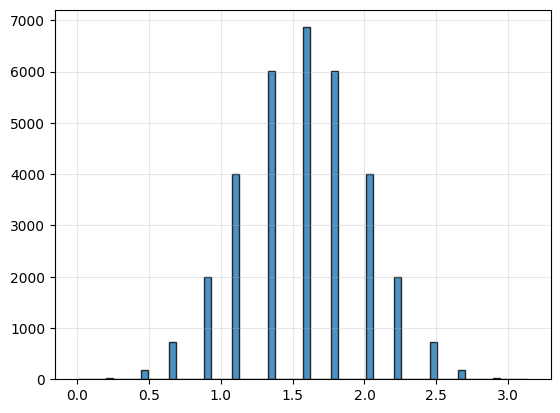

(8, 8)


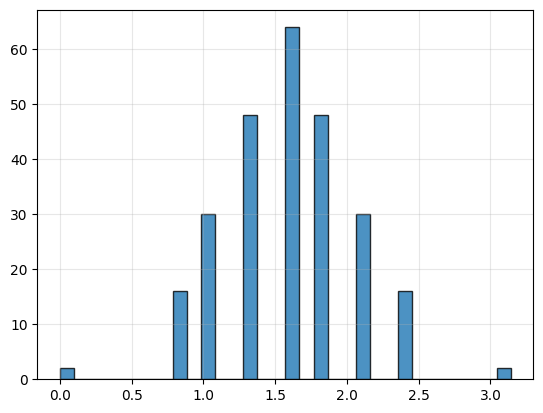

(24, 24)


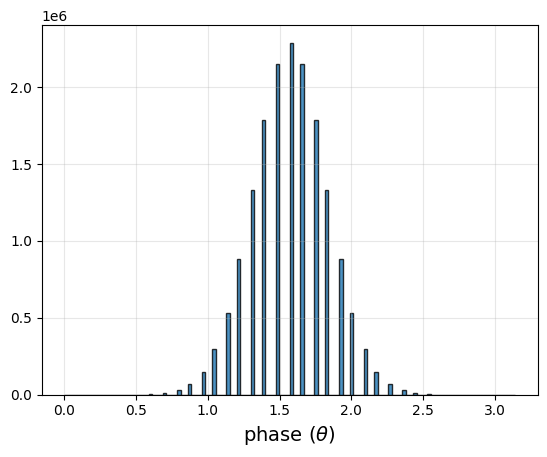

0

In [38]:
# Plotting three histograms. line q = 15, cayley 4, cayley 12

#line 15
q_line15 = 15
adj_q_15 = adj_line(q_line15)
Q_15 = QuantumSystem(q_line15, adj_q_15)

phases_15 = Q_15.phases(q, adj_q_15).reshape(-1)
Q_15.G_theta_hist(phases_15)

# cayley 4
q_cayley4 = 8
adj_cayley_4_list = [[0,1],[1,2],[2,3],[3,0],[4,5],[5,6],[6,7],[7,4],[0,4],[1,5],[2,6],[3,7]]
adj_cayley_4 = sparse_to_dense(q_cayley4, adj_cayley_4_list)
Q_cayley_4 = QuantumSystem(q_cayley4, adj_cayley_4)
phases_cayley4 = Q_cayley_4.phases(q_cayley4, adj_cayley_4).reshape(-1)
Q_cayley_4.G_theta_hist(phases_cayley4)

# cayley 12
q_cayley12 = 24
adj_cayley_12_list = [[0,1],[1,2],[2,3],[3,4],[4,5],[5,6],[6,7],[7,8],[8,9],[9,10],[10,11],[11,0],[12,13],[13,14],[14,15],[15,16],[16,17],[17,18],[18,19],[19,20],[20,21],[21,22],[22,23],[23,12],[0,12],[1,13],[2,14],[3,15],[4,16],[5,17],[6,18],[7,19],[8,20],[9,21],[10,22],[11,23]]
adj_cayley_12 = sparse_to_dense(q_cayley12, adj_cayley_12_list)
Q_cayley_12 = QuantumSystem(q_cayley12, adj_cayley_12)
phases_cayley12 = Q_cayley_12.phases(q_cayley12, adj_cayley_12).reshape(-1)
Q_cayley_12.G_theta_hist(phases_cayley12, labels = ['x'])


#### Plot revisions: Star Graph, Cumulative probabilities etc.

In [7]:
# Plotting cumulative probabilities for line and grid; along with individual probabilities

# Line graph q =10, grid q = 9, grid q = 25.
# cumulative and individual probabilities for each

it = 35+1     # it = 35

# data for line graph q = 10
q_line10 = 10
adj_line10 = adj_line(q_line10)
Q_line10 = QuantumSystem(q_line10, adj_line10)
_ = Q_line10.prob_m(200)
line_prob_indiv = [Q_line10.cached_probs[i] for i in range(1,it)]

line_prob_cumul = []
cumulative_count_line = 1
for i in line_prob_indiv:
    cumulative_count_line *= i
    line_prob_cumul.append(cumulative_count_line)
    
print('line prob indiv', line_prob_indiv)
print('line prob cumul', line_prob_cumul)

#doing the same for grid q = 9, and q = 25

q_grid9 = 9
adj_grid9_list = [[0,1],[1,2],[3,4],[4,5],[6,7],[7,8],[0,3],[1,4],[2,5],[3,6],[4,7],[5,8]]  # grid graph 3 x 3. nomenclature is from left to right from top to bottom, starting from 0
Q_grid9 = QuantumSystem(q_grid9, sparse_to_dense(q_grid9, adj_grid9_list))
_ = Q_grid9.prob_m(200)
grid9_prob_indiv = [Q_grid9.cached_probs[i] for i in range(1,it)]

grid9_prob_cumul = []
cumulative_count_grid = 1
for i in grid9_prob_indiv:
    cumulative_count_grid *= i
    grid9_prob_cumul.append(cumulative_count_grid)

print('grid9 prob indiv', grid9_prob_indiv)
print('grid9 prob cumul', grid9_prob_cumul)

q_grid16 = 16
adj_grid16_list = [[0,1],[1,2],[2,3],[4,5],[5,6],[6,7],[8,9],[9,10],[10,11],[12,13],[13,14],[14,15],[0,4],[1,5],[2,6],[3,7],[4,8],[5,9],[6,10],[7,11],[8,12],[9,13],[10,14],[11,15]]
Q_grid16 = QuantumSystem(q_grid16, sparse_to_dense(q_grid16, adj_grid16_list))
_ = Q_grid16.prob_m(200)
grid16_prob_indiv = [Q_grid16.cached_probs[i] for i in range(1,it)]

grid16_prob_cumul = []
cumulative_count_grid16 = 1
for i in grid16_prob_indiv:
    cumulative_count_grid16 *= i
    grid16_prob_cumul.append(cumulative_count_grid16)

print('grid16 prob indiv', grid16_prob_indiv)
print('grid16 prob cumul', grid16_prob_cumul)





line prob indiv [0.5004887585532746, 0.6071723282861873, 0.6765105609945916, 0.7263294198900552, 0.7639926134788089, 0.7934499201236269, 0.8170788598262729, 0.8364138041699694, 0.8524944708197459, 0.8660519268903083, 0.8776155821080606, 0.8875782250478141, 0.8962372978357519, 0.9038220479229829, 0.9105119413133453, 0.9164494587404474, 0.9217491521094804, 0.9265041426690801, 0.930790841044437, 0.934672423690131, 0.938201438534865, 0.9414217995414691, 0.9443703488364783, 0.9470781071965355, 0.9495712933691383, 0.9518721655835543, 0.9539997210562541, 0.9559702783706994, 0.9577979610382177, 0.9594950966668191, 0.9610725438419423, 0.9625399573269057, 0.9639060010852522, 0.9651785176755906, 0.9663646616614278]
line prob cumul [0.5004887585532746, 0.30388292481185514, 0.20558000794114542, 0.14931880790888508, 0.11407846629584935, 0.09051554997026753, 0.07395834236625423, 0.06185977848866372, 0.05273511912772008, 0.04567135153535193, 0.040081889763359746, 0.035575812572725, 0.03188437012849022

In [34]:
#4 x 4 : finding probs of optimal solutions.

# sorting the prob list's top 20 elts. and seeing it evolve over iterations

for k in range(151):
    out = Q_grid16.psi_iter_m_alt(2*k)
    print(f'\n{2*k}')
    # print(out)
    out_amp = np.array(sorted(np.abs(out), reverse = 1))
    out_prob= np.round((out_amp)**2, 10)
    print(out_prob[:50])
    print('prob sum total        = ', np.sum(out_amp**2))
    print('prob sum optimal soln = ', out_prob[0]+out_prob[1])



0
[1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05
 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05
 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05
 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05 1.5259e-05]
prob sum total        =  1.0000152590218967
prob sum optimal soln =  3.0518e-05

2
[5.58883e-05 5.58883e-05 5.40002e-05 5.40002e-05 5.40002e-05 5.40002e-05 5.40002e-05 5.40002e-05 5.40002e-05 5.40002e-05 5.17150e-05 5.17150e-05
 5.17150e-05 5.17150e-05 5.17150e-05 5.17150e-05 5.17150e-05 5.17150e-05 5.17150e-05 5.17150e-05 5.17150e-05 5.17150e-05 5.17150e-05 5.17150e-05
 5.17150e-05 5.17150e-05 5.17150e-05 5.17150e-05 5.17150e-05 5.17150e

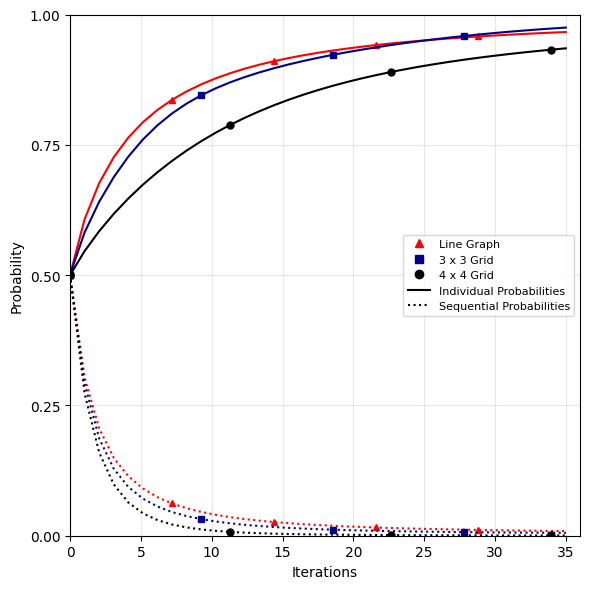

In [8]:
#plotting line, 3x3, 4x4 grid success probabilities : sequence cumulative measurement and individual measurement.

x = np.linspace(0, it-1, it-1)          # eg. it = 51 means 50 iterations

# Define y-axis values
spacing = 7

m = ['^', 'o', 's']
col = ['black', 'darkblue']

plt.figure(figsize=(6, 6))

# Plot curves with spaced markers
plt.plot(x, line_prob_indiv, color='red', linestyle='-', marker=m[0], markevery=spacing, markersize=5)
plt.plot(x, grid9_prob_indiv, color='darkblue', linestyle='-', marker=m[2], markevery=spacing+2, markersize=5)
plt.plot(x, grid16_prob_indiv, color='black', linestyle='-', marker=m[1], markevery=spacing+4, markersize=5)

plt.plot(x, line_prob_cumul, color='red', linestyle=':', marker=m[0], markevery=spacing, markersize=5)
plt.plot(x, grid9_prob_cumul, color='darkblue', linestyle=':', marker=m[2], markevery=spacing+2, markersize=5)
plt.plot(x, grid16_prob_cumul, color='black', linestyle=':', marker=m[1], markevery=spacing+4, markersize=5)

plt.xlim(0, it)
plt.ylim(0, 1)
plt.yticks([0,.25, 0.5, .75, 1])
plt.xlabel('Iterations')
plt.ylabel('Probability')
# plt.title('Individual and Sequential Measurement Probabilities')

# Custom legend
from matplotlib.lines import Line2D
custom_lines = [
    Line2D([0], [0], color='red', marker='^', markersize=6, linestyle='None', label='Line Graph'),
    Line2D([0], [0], color='darkblue', marker='s', markersize=6, linestyle='None', label='3 x 3 Grid'),
    Line2D([0], [0], color='black', marker='o', markersize=6, linestyle='None', label='4 x 4 Grid'),
    Line2D([0], [0], color='black', linestyle='-', linewidth=1.5, label='Individual Probabilities'),
    Line2D([0], [0], color='black', linestyle=':', linewidth=1.5, label='Sequential Probabilities')
]
plt.legend(handles=custom_lines, loc='right', fontsize=8)

plt.grid(alpha = .3)
plt.tight_layout()
plt.show()

(16, 16)
(16, 16)


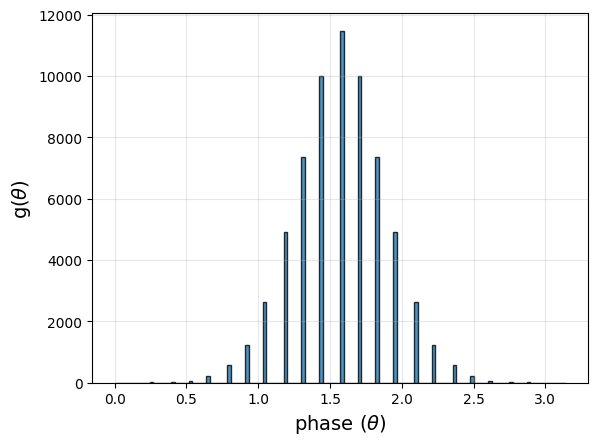

0

In [ ]:
#histogram of 4x4 grid graph

q_grid16 = 16
adj_grid16_list = [[0,1],[1,2],[2,3],[4,5],[5,6],[6,7],[8,9],[9,10],[10,11],[12,13],[13,14],[14,15],[0,4],[1,5],[2,6],[3,7],[4,8],[5,9],[6,10],[7,11],[8,12],[9,13],[10,14],[11,15]]
Q_grid16 = QuantumSystem(q_grid16, sparse_to_dense(q_grid16, adj_grid16_list))
# phases_grid16 = Q_grid16.phases(q_grid16, sparse_to_dense(q_grid16, adj_grid16_list)).reshape(-1)
# Q_grid16.G_theta_hist(phases_grid16, labels = ['x','y'])

# phases_cayley4 = Q_cayley_4.phases(q_cayley4, adj_cayley_4).reshape(-1)
# Q_cayley_4.G_theta_hist(phases_cayley4)





(16, 16)


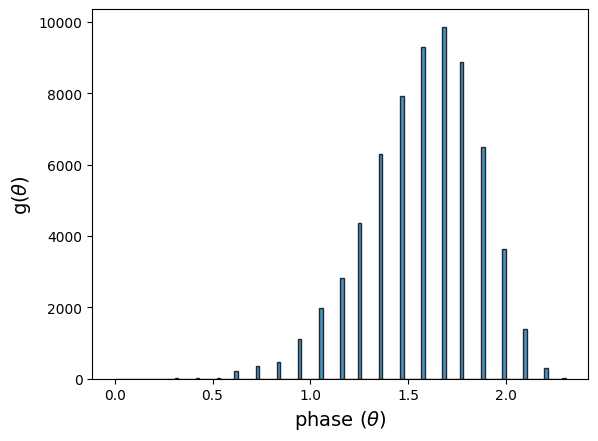

0

In [5]:
#ring star graph histogram
q_ring_star = 16
adj_ring_star_list = [[0,1],[1,2],[2,3],[3,4],[4,5],[5,6],[6,7],[7,8],[8,9],[9,10],[10,11],[11,12],[12,13],[13,14],[14,0],[0,15],[1,15],[2,15],[3,15],[4,15],[5,15],[6,15],[7,15],[8,15],[9,15],[10,15],[11,15],[12,15],[13,15],[14,15]]
adj_ring_star = sparse_to_dense(q_ring_star, adj_ring_star_list)
Q_ring_star = QuantumSystem(q_ring_star, adj_ring_star)
phases_ring_star = Q_ring_star.phases(q_ring_star, adj_ring_star).reshape(-1)
Q_ring_star.G_theta_hist(phases_ring_star, labels = ['x','y'])

In [115]:
#ring star graph - optimal solutions' and sequential measurements' probabilities 
q_ring_star = 16
adj_ring_star_list = [[0,1],[1,2],[2,3],[3,4],[4,5],[5,6],[6,7],[7,8],[8,9],[9,10],[10,11],[11,12],[12,13],[13,14],[14,0],[0,15],[1,15],[2,15],[3,15],[4,15],[5,15],[6,15],[7,15],[8,15],[9,15],[10,15],[11,15],[12,15],[13,15],[14,15]]
adj_ring_star = sparse_to_dense(q_ring_star, adj_ring_star_list)
Q_ring_star = QuantumSystem(q_ring_star, adj_ring_star)

it = 125+1
_ = Q_ring_star.prob_m(it+10)
ring_star_prob_indiv = [Q_ring_star.cached_probs[i] for i in range(1,it)]

#cumulative prob part
ring_star_prob_cumul = []
cumulative_count_ring_star = 1
for i in ring_star_prob_indiv:
    cumulative_count_ring_star *= i
    ring_star_prob_cumul.append(cumulative_count_ring_star)
print('ring_star prob indiv \n', ring_star_prob_indiv)
print('ring_star prob cumul \n', ring_star_prob_cumul)

# probing prob sum of optimal sol 
prob_sum_opt_ring_star = []
for k in range(it):
    out = Q_ring_star.psi_iter_m_alt(k)
    print(f'\n{k}')
    # print(out)
    out_amp = np.array(sorted(np.abs(out), reverse = 1))
    out_prob= np.round((out_amp)**2, 10)
    prob_sum_opt = np.sum(out_prob[:30])
    prob_sum_opt_ring_star.append(prob_sum_opt)
    print(out_prob[:50])
    print('prob sum total        = ', np.sum(out_amp**2))
    print('prob sum optimal soln = ', prob_sum_opt)            # coZ there are 2*15 = 30 optimal degenerate solutions for this odd-vertexed graph.

print('prob_optimal_soln_ring_star', prob_sum_opt_ring_star)

(16, 16)
ring_star prob indiv 
 [0.5010409427023337, 0.5385778615220063, 0.5667163887297697, 0.5892057191268826, 0.6078747237941996, 0.6237817394894044, 0.6375994452256213, 0.6497828266631474, 0.6606538811221083, 0.6704485889226035, 0.6793448096330506, 0.6874797513878892, 0.6949613819899636, 0.7018761386435407, 0.7082942807404059, 0.7142736910171654, 0.7198626278678758, 0.7251017533634706, 0.7300256520016024, 0.7346639855724127, 0.7390423840795243, 0.7431831424072995, 0.7471057719827702, 0.7508274426887617, 0.7543633405982667, 0.7577269603196738, 0.7609303459426223, 0.7639842911367171, 0.7668985064634773, 0.7696817601330515, 0.7723419970779871, 0.774886440193571, 0.7773216768152195, 0.7796537329032098, 0.78188813693756, 0.7840299751581138, 0.7860839394929402, 0.7880543692844175, 0.789945287733899, 0.7917604338328199, 0.7935032904230995, 0.7951771089270789, 0.796784931202517, 0.7983296089080257, 0.7998138207059233, 0.8012400875807613, 0.8026107865109747, 0.8039281626968197, 0.8051943405

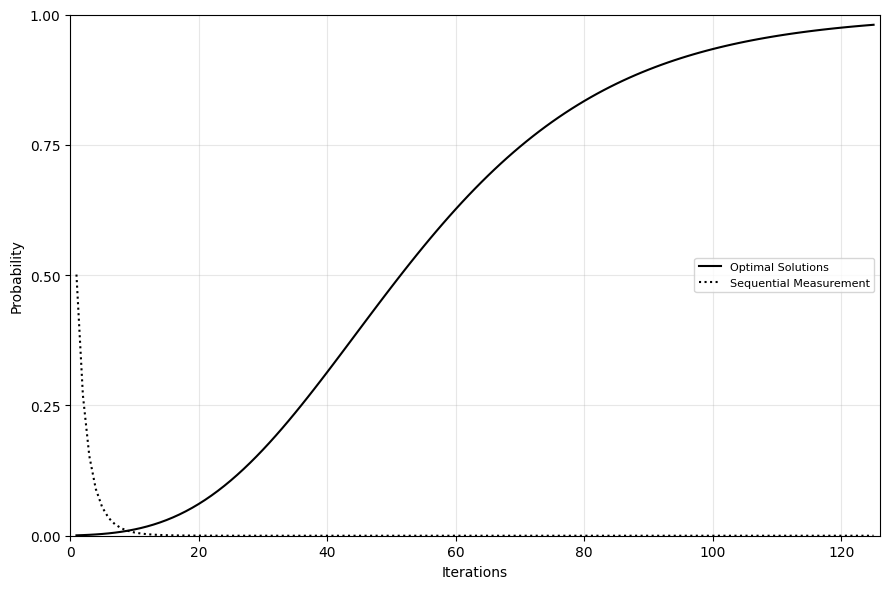

In [116]:
#plotting: star-ring graph's success probabilities : sequence cumulative measurement and optimal solutions.
# it = 35+1

x = np.linspace(0, it-1, it)[1:]          # 0 to 35 with 36 iuntermediate points, but ignoring the zeroth one. total 35 points for plotting on the x axis, starting from 1.
y_opt = np.array(prob_sum_opt_ring_star[1:it])       # 35 values of prob_sum_opt starting from first iteration
y_cumul = np.array(ring_star_prob_cumul)        # 35 values for prob_cumul starting from first iteration

# Define y-axis values
spacing = 7

m = ['^', 'o', 's']

plt.figure(figsize=(9, 6))

# Plot curves with spaced markers
# plt.plot(x, line_prob_indiv, color='red', linestyle='-', marker=m[0], markevery=spacing, markersize=5)
# plt.plot(x, grid9_prob_indiv, color='darkblue', linestyle='-', marker=m[2], markevery=spacing+2, markersize=5)
plt.plot(x, y_opt, color='black', linestyle='-') #, marker=m[1], markevery=spacing+4, markersize=5)

# plt.plot(x, line_prob_cumul, color='red', linestyle=':', marker=m[0], markevery=spacing, markersize=5)
# plt.plot(x, grid9_prob_cumul, color='darkblue', linestyle=':', marker=m[2], markevery=spacing+2, markersize=5)
plt.plot(x, y_cumul, color='black', linestyle=':') #, marker=m[1], markevery=spacing+4, markersize=5)

plt.xlim(0, it)
plt.ylim(0, 1)
plt.yticks([0,.25, 0.5, .75, 1])
plt.xlabel('Iterations')
plt.ylabel('Probability')
# plt.title('Individual and Sequential Measurement Probabilities')

# Custom legend
from matplotlib.lines import Line2D
custom_lines = [
    # Line2D([0], [0], color='red', marker='^', markersize=6, linestyle='None', label='Line Graph'),
    # Line2D([0], [0], color='darkblue', marker='s', markersize=6, linestyle='None', label='3 x 3 Grid'),
    # Line2D([0], [0], color='black', marker='o', markersize=6, linestyle='None'),
    Line2D([0], [0], color='black', linestyle='-', linewidth=1.5, label='Optimal Solutions'),
    Line2D([0], [0], color='black', linestyle=':', linewidth=1.5, label='Sequential Measurement')
]
plt.legend(handles=custom_lines, loc='right', fontsize=8)

plt.grid(alpha = .3)
plt.tight_layout()
plt.show()

In [70]:
# x = np.linspace(0, it-1, it)[1:]     
# y = prob_sum_opt_ring_star[:36]
# len(y)
# (ring_star_prob_indiv)
np.array(ring_star_prob_cumul[1:])
x

array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13., 14., 15., 16., 17., 18., 19., 20., 21., 22., 23., 24., 25., 26., 27., 28.,
       29., 30., 31., 32., 33., 34., 35.])

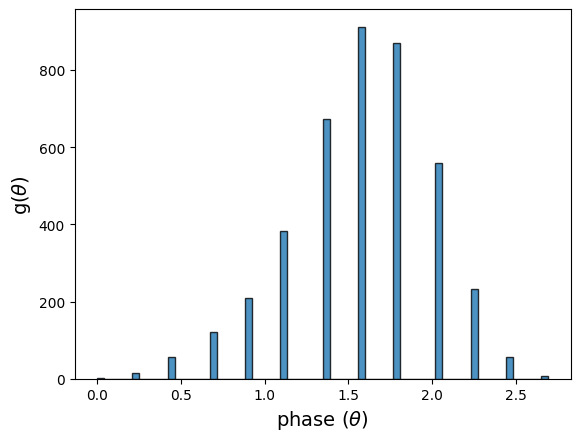

0

In [ ]:

# cayley 4
# q_cayley4 = 8
# adj_cayley_4_list = [[0,1],[1,2],[2,3],[3,0],[4,5],[5,6],[6,7],[7,4],[0,4],[1,5],[2,6],[3,7]]
# adj_cayley_4 = sparse_to_dense(q_cayley4, adj_cayley_4_list)
# Q_cayley_4 = QuantumSystem(q_cayley4, adj_cayley_4)
# phases_cayley4 = Q_cayley_4.phases(q_cayley4, adj_cayley_4).reshape(-1)
# Q_cayley_4.G_theta_hist(phases_cayley4)



#for lollipop graph
q_lol = 12
# adj_lol_list = [[0,1],[1,2],[2,3],[3,0],[4,5],[5,6],[6,7],[7,4],[0,4],[1,5],[2,6],[3,7]]
# adj_lol = sparse_to_dense(q_lol, adj_lol_list)
# adj_lol = np.array([[0,1,1,1,0,0,0,0],[1,0,1,1,0,0,0,0],[1,1,0,1,0,0,0,0],[1,1,1,0,1,0,0,0],[0,0,0,1,0,1,0,0],[0,0,0,0,1,0,1,0],[0,0,0,0,0,1,0,1],[0,0,0,0,0,0,1,0]])
adj_lol = np.array([[0,1,1,1,0,0,0,0,0,0,0,0],[1,0,1,1,0,0,0,0,0,0,0,0],[1,1,0,1,0,0,0,0,0,0,0,0],[1,1,1,0,1,0,0,0,0,0,0,0],[0,0,0,1,0,1,0,0,0,0,0,0],[0,0,0,0,1,0,1,0,0,0,0,0],[0,0,0,0,0,1,0,1,0,0,0,0],[0,0,0,0,0,0,1,0,1,0,0,0],[0,0,0,0,0,0,0,1,0,1,0,0],[0,0,0,0,0,0,0,0,1,0,1,0],[0,0,0,0,0,0,0,0,0,1,0,1],[0,0,0,0,0,0,0,0,0,0,1,0]])

Q_lol = QuantumSystem(q_lol, adj_lol)
phases_lol = Q_lol.phases(q_lol, adj_lol).reshape(-1)
# Q_cayley_4.G_theta_hist(phases_lol)
Q_lol.G_theta_hist(phases_lol, labels = ['x','y'])


(6, 6)
adj_k3_k3
 [[0. 1. 1. 0. 0. 0.]
 [1. 0. 1. 0. 0. 0.]
 [1. 1. 0. 1. 0. 0.]
 [0. 0. 1. 0. 1. 1.]
 [0. 0. 0. 1. 0. 1.]
 [0. 0. 0. 1. 1. 0.]]


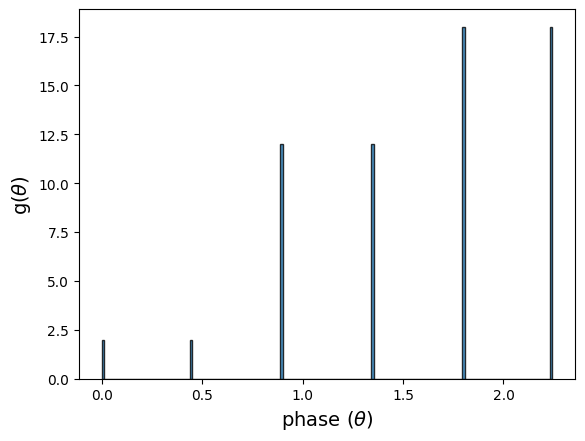

counter for phases_k3_k3 Counter({2.243994752564138: 18, 1.7951958020513104: 18, 0.8975979010256552: 12, 1.3463968515384828: 12, 0.0: 2, 0.4487989505128276: 2})
phase 0.0 degrees occurs 2 times
phase 51.42857142857143 degrees occurs 12 times
phase 77.14285714285715 degrees occurs 12 times
phase 25.714285714285715 degrees occurs 2 times
phase 128.57142857142856 degrees occurs 18 times
phase 102.85714285714286 degrees occurs 18 times
(6, 6)
adj_star_plus_triangle
 [[0. 1. 1. 1. 1. 1.]
 [1. 0. 1. 1. 0. 0.]
 [1. 1. 0. 1. 0. 0.]
 [1. 1. 1. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]]


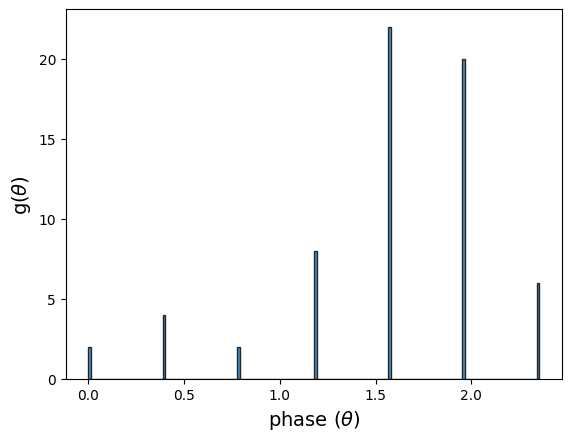

counter for phases_star_plus_triangle Counter({1.5707963267948966: 22, 1.9634954084936207: 20, 1.1780972450961724: 8, 2.356194490192345: 6, 0.39269908169872414: 4, 0.0: 2, 0.7853981633974483: 2})
phase 0.0 degrees occurs 2 times
phase 22.5 degrees occurs 4 times
phase 45.0 degrees occurs 2 times
phase 67.5 degrees occurs 8 times
phase 90.0 degrees occurs 22 times
phase 112.5 degrees occurs 20 times
phase 135.0 degrees occurs 6 times


In [24]:
#Checking for double-peaked phase distribution graphs
# k3_k3 graph
n = q_k3_k3 = 6
adj_k3_k3 = sparse_to_dense(6, [[0,1],[0,2],[1,0], [1,2],[2,0],[2,1],[2,3],[3,2],[3,4],[3,5],[4,3],[4,5],[5,3],[5,4]])
print('adj_k3_k3\n', adj_k3_k3)

Q_k3_k3 = QuantumSystem(q_k3_k3, adj_k3_k3)
phases_k3_k3 = Q_k3_k3.phases(q_k3_k3, adj_k3_k3).reshape(-1)
Q_k3_k3.G_theta_hist(phases_k3_k3, labels = ['x','y'], num_bins = 164)

print('counter for phases_k3_k3', collections.Counter(phases_k3_k3))
for k, v in collections.Counter(phases_k3_k3).items():
    print(f'phase {k*180/np.pi} degrees occurs {v} times')


# star plus triangle on 6 verttices graph
n = q_star_plus_triangle = 6
adj_star_plus_triangle = sparse_to_dense(6, [[0,1],[0,2],[0,3],[0,4],[0,5],[1,0],[1,2],[1,3],[2,0],[2,1],[2,3],[3,0],[3,1],[3,2],[4,0],[5,0]])
print('adj_star_plus_triangle\n', adj_star_plus_triangle)

Q_star_plus_triangle = QuantumSystem(q_star_plus_triangle, adj_star_plus_triangle)
phases_star_plus_triangle = Q_star_plus_triangle.phases(q_star_plus_triangle, adj_star_plus_triangle).reshape(-1)
Q_star_plus_triangle.G_theta_hist(phases_star_plus_triangle, labels = ['x','y'], num_bins = 164)

print('counter for phases_star_plus_triangle', collections.Counter(phases_star_plus_triangle))
for k, v in collections.Counter(phases_star_plus_triangle).items():
    print(f'phase {k*180/np.pi} degrees occurs {v} times')




#For second exam plots

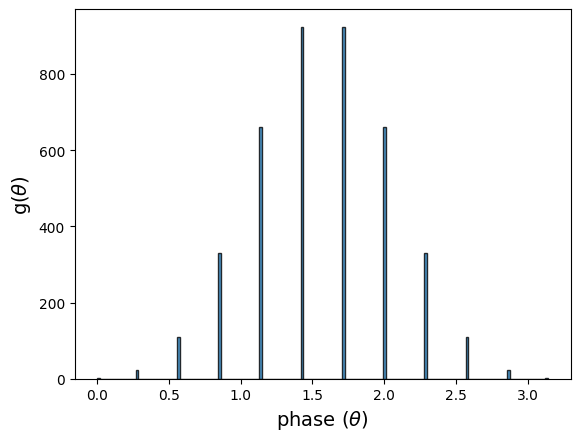

[0.         0.28559933 0.57119866 0.28559933 0.57119866 0.856798   0.57119866 0.28559933 0.57119866 0.856798  ]
sum of amps_init: 8191.999999999999
phases at 1 iterations [0.         1.71359599 1.85639566 1.71359599 1.85639566 1.99919533 1.85639566 1.71359599 1.85639566 1.99919533]


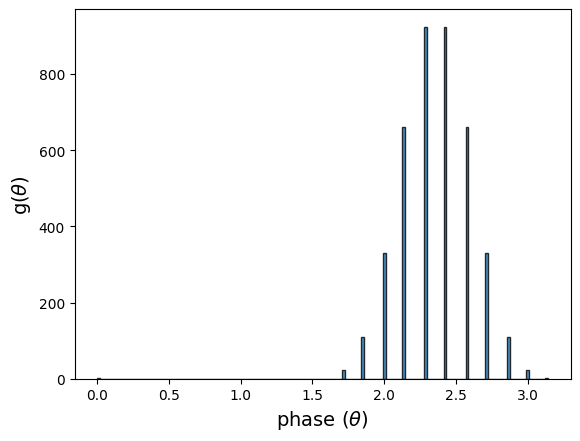

sum of amps_init: 8191.999999999999
phases at 2 iterations [0.         3.42719199 3.71279132 3.42719199 3.71279132 3.99839065 3.71279132 3.42719199 3.71279132 3.99839065]


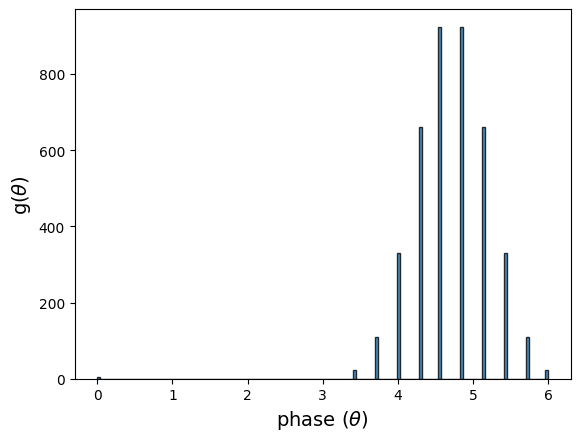

sum of amps_init: 8191.999999999999
phases at 5 iterations [0.         2.28479466 2.99879299 2.28479466 2.99879299 3.71279132 2.99879299 2.28479466 2.99879299 3.71279132]


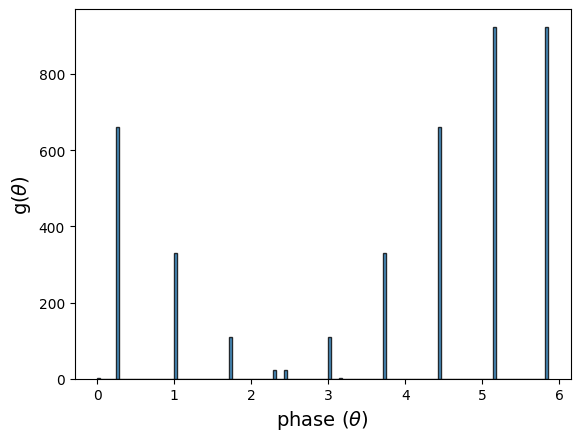

sum of amps_init: 8191.999999999999
phases at 10 iterations [0.         4.56958931 5.99758598 4.56958931 5.99758598 1.14239733 5.99758598 4.56958931 5.99758598 1.14239733]


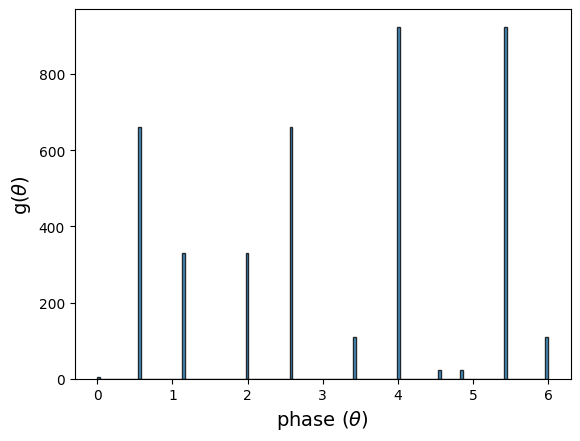

sum of amps_init: 8191.999999999999
phases at 15 iterations [0.         0.57119866 2.71319366 0.57119866 2.71319366 4.85518865 2.71319366 0.57119866 2.71319366 4.85518865]


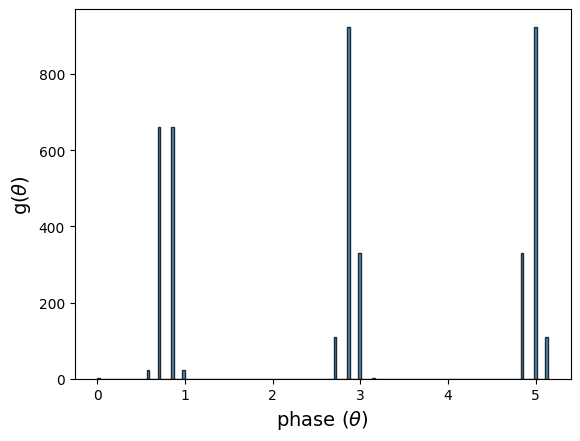

In [25]:
# line graph with 12 vertices
q_line12 = 12
adj_line12 = adj_line(q_line12)
Q_line12 = QuantumSystem(q_line12, adj_line12)
phases_line12 = Q_line12.phases(q_line12, adj_line12).reshape(-1)
Q_line12.G_theta_hist(phases_line12, labels = ['x','y'], num_bins = 164)

print(phases_line12[:10]        )

# now plotting the phases distribution after 10 iterations of the quantum state evolution
# it = 1
# pm = Q_line12.phase_m(it)        # this will return the phase angles at the mth iteration, which is 10 here. now create the histogram
# # pm[:10]
# Q_line12.G_theta_hist(Q_line12.phase_m(it), labels = ['x','y'], num_bins = 164)


# # plotting the phases distribution after 2, 5, 10, 15 iterations
for it in [1, 2, 5, 10, 15]:
    pm = Q_line12.phase_m(it)        # this will return the phase angles at the mth iteration, which is 10 here. now create the histogram
    print(f'phases at {it} iterations', pm[:10])
    Q_line12.G_theta_hist(pm, labels = ['x','y'], num_bins = 164)


In [ ]:
ang = Q_line12.phase_angles

# [i for i in ang if i > 3]


[array([3.14159265]), array([3.14159265])]